# 03 — DNABERT-2 LoRA Fine-Tuning + Probing

**Goal of this notebook**: answer the core research question from our proposal —
*how much does LoRA fine-tuning improve the learned DNA representations compared to the frozen pretrained backbone?*

**Experimental design** (controlled comparison):

| Variable                | Frozen baseline (Notebooks 01 + 02)    | This notebook                          |
|-------------------------|----------------------------------------|----------------------------------------|
| Backbone                | Frozen DNABERT-2                        | **LoRA-tuned DNABERT-2**               |
| Tap layers              | L0, L1, L3, L6, L8, L10, L12, avg_last4 | Same                                   |
| Pooling                 | mean, max, cls                          | Same                                   |
| Probe                   | Linear, MLP (768→256→32→2)             | Same                                   |
| Train / val / test split| 80 / 20 / held-out                      | Same (same SPLIT_SEED=42)              |
| Seeds (probe training)  | 3 (42, 123, 456)                        | Same                                   |

Only the **backbone** differs between the two conditions → the delta is attributable to LoRA.

**Pipeline**:
1. Train a LoRA adapter (1 seed is enough — probe-level seeding handles variance)
2. Merge the adapter into the backbone, extract all-layer embeddings to `./embedding_cache_lora/`
3. Run identical probing protocol on LoRA embeddings (`./embedding_cache_lora/`)
4. Load frozen probing results from `probe_results_v2.csv` and compare paired layers

**Supplementary data points** retained from earlier experiments (no re-run needed):
- Original LoRA (Wqkv only, L12, Linear head, test@final): **F1 = 0.8716 ± 0.0041** — under-specified baseline
- Fixed LoRA (Wqkv + gated_layers + wo, L12, Linear head, test@final): **F1 = 0.9200 ± 0.0043** — end-to-end deployment baseline

These numbers are included in the final comparison table as *deployment-style* baselines.

---

## Notebook structure

- §1 Config & dataset
- §2 LoRA model class
- §3 Train LoRA adapter (single seed), save checkpoint
- §4 Load LoRA backbone, extract all-layer embeddings to cache
- §5 Probe LoRA embeddings (linear + MLP × 8 layers × 3 poolings × 3 seeds)
- §6 Compare with frozen baseline — paired table, delta heatmap, best-layer migration
- §7 Final combined results table for the report

## 1. Config & Dataset

In [1]:
import os
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model, PeftModel
from genomic_benchmarks.dataset_getters.pytorch_datasets import get_dataset
from tqdm import tqdm

# =========================  Paths  =========================
MODEL_DIR        = './dnabert2'
LORA_CKPT_DIR    = './lora_adapter'           # where the trained LoRA adapter is saved
LORA_CACHE_DIR   = './embedding_cache_lora'   # embeddings from LoRA-tuned backbone
FROZEN_CACHE_DIR = './embedding_cache'        # embeddings from frozen backbone (from Notebook 01)
FROZEN_PROBE_CSV = 'probe_results_v2.csv'     # frozen probe results (from Notebook 02_v2)

DATASET_NAME = 'human_nontata_promoters'
DEVICE       = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ==================  Training hyperparameters  ==================
MAX_LENGTH       = 512
BATCH_SIZE       = 32
LORA_TRAIN_SEED  = 42           # one seed is enough for the backbone (probing reseeds)
VAL_FRAC_LORA    = 0.1          # 10% of train → val, for LoRA early-stopping / epoch selection

LORA_CONFIG = {
    'r':              8,
    'lora_alpha':     16,
    'lora_dropout':   0.05,
    'target_modules': ['Wqkv', 'gated_layers', 'wo'],
}

TRAIN_CONFIG = {
    'backbone_lr':  1e-4,
    'head_lr':      1e-3,
    'epochs':       8,
    'warmup_steps': 50,
    'weight_decay': 0.01,
    'grad_clip':    1.0,
}

# ==================  Extraction / probing grid  ==================
HIDDEN_DIM   = 768
NUM_CLASSES  = 2
LAYER_KEYS   = [0, 1, 3, 6, 8, 10, 12, 'avg_last4']  # same as Notebook 02 v2
POOL_NAMES   = ['mean', 'max', 'cls']
PROBE_TYPES  = ['linear', 'mlp']
PROBE_SEEDS  = [42, 123, 456]
VAL_RATIO    = 0.2
SPLIT_SEED   = 42                # MUST match Notebook 02 v2 for paired comparison
PROBE_BATCH  = 256
PROBE_CONFIG = {
    'linear': {'lr': 1e-3, 'epochs': 10},
    'mlp':    {'lr': 1e-3, 'epochs': 20},
}
# ============================================================

print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
os.makedirs(LORA_CKPT_DIR,  exist_ok=True)
os.makedirs(LORA_CACHE_DIR, exist_ok=True)

E:\anaconda\envs\nlp_dl\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
GPU: NVIDIA GeForce RTX 5090


In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, trust_remote_code=True)

train_gb_full = get_dataset(DATASET_NAME, split='train')
test_gb       = get_dataset(DATASET_NAME, split='test')
print(f'Train (full): {len(train_gb_full)} | Test: {len(test_gb)}')

class DnaDataset(Dataset):
    """Tokenize on the fly — same class used in Notebooks 01 and 03(fixed)."""
    def __init__(self, base_dataset, tokenizer, max_length=MAX_LENGTH):
        self.base_dataset = base_dataset
        self.tokenizer    = tokenizer
        self.max_length   = max_length
    def __len__(self):
        return len(self.base_dataset)
    def __getitem__(self, idx):
        sequence, label = self.base_dataset[idx]
        enc = self.tokenizer(
            sequence, truncation=True, padding='max_length',
            max_length=self.max_length, return_tensors='pt',
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item['labels'] = torch.tensor(label, dtype=torch.long)
        return item

train_full_dataset = DnaDataset(train_gb_full, tokenizer)
test_dataset       = DnaDataset(test_gb,       tokenizer)
test_loader_ft     = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f'Test batches (for LoRA eval during training): {len(test_loader_ft)}')

Train (full): 27097 | Test: 9034
Test batches (for LoRA eval during training): 283


## 2. Model: DNABERT-2 + LoRA (attention + FFN)

Target modules: `Wqkv`, `gated_layers`, `wo` — covers attention QKV + GeGLU FFN in every layer.
The classifier head is a single Linear(768 → 2); it is only used during LoRA training and is
discarded afterwards (we only need the adapted backbone for probing).

In [3]:
class DNABERT2LoRAClassifier(nn.Module):
    def __init__(self, model_dir, lora_cfg, num_classes=2, head_dropout=0.1):
        super().__init__()
        backbone    = AutoModel.from_pretrained(model_dir, trust_remote_code=True)
        hidden_size = backbone.config.hidden_size

        lora_config = LoraConfig(
            r=lora_cfg['r'],
            lora_alpha=lora_cfg['lora_alpha'],
            target_modules=lora_cfg['target_modules'],
            lora_dropout=lora_cfg['lora_dropout'],
            bias='none',
        )
        self.backbone   = get_peft_model(backbone, lora_config)
        self.dropout    = nn.Dropout(head_dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)
        nn.init.xavier_uniform_(self.classifier.weight)
        nn.init.zeros_(self.classifier.bias)

    @staticmethod
    def mean_pool(hidden_states, attention_mask):
        mask   = attention_mask.unsqueeze(-1).float()
        summed = (hidden_states * mask).sum(dim=1)
        counts = mask.sum(dim=1).clamp(min=1e-9)
        return summed / counts

    def forward(self, input_ids, attention_mask, labels=None):
        out         = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
        last_hidden = out[0]
        pooled      = self.mean_pool(last_hidden, attention_mask)
        pooled      = self.dropout(pooled)
        logits      = self.classifier(pooled)
        loss        = nn.CrossEntropyLoss()(logits, labels) if labels is not None else None
        return {'loss': loss, 'logits': logits}

# Quick trainable-param sanity check
_tmp = DNABERT2LoRAClassifier(MODEL_DIR, LORA_CONFIG)
total     = sum(p.numel() for p in _tmp.parameters())
trainable = sum(p.numel() for p in _tmp.parameters() if p.requires_grad)
print(f'Total params:      {total:>12,}')
print(f'Trainable params:  {trainable:>12,}  ({trainable/total*100:.2f}%)')
del _tmp
if torch.cuda.is_available():
    torch.cuda.empty_cache()

C:\Users\JxxC\.cache\huggingface\modules\transformers_modules\dnabert2\bert_layers.py:126: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at ./dnabert2 and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Total params:       118,397,186
Trainable params:     1,328,642  (1.12%)


## 3. Train LoRA Adapter (single seed) & Save Checkpoint

We train for 8 epochs, select the epoch with the best **val F1** (val is 10% held out from train),
and save that checkpoint's adapter weights to `./lora_adapter/`. The test set is evaluated at every
epoch only for a sanity curve — selection uses val, not test.

In [4]:
def build_optimizer(model, train_cfg):
    head_params, backbone_params = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (head_params if name.startswith('classifier') else backbone_params).append(p)
    return torch.optim.AdamW(
        [
            {'params': backbone_params, 'lr': train_cfg['backbone_lr']},
            {'params': head_params,     'lr': train_cfg['head_lr']},
        ],
        weight_decay=train_cfg['weight_decay'],
    )

def train_one_epoch(model, loader, optimizer, scheduler, device, grad_clip=1.0):
    model.train()
    total_loss = 0.0
    for batch in tqdm(loader, desc='train', leave=False):
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)
        optimizer.zero_grad()
        loss = model(input_ids, attention_mask, labels=labels)['loss']
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            (p for p in model.parameters() if p.requires_grad), max_norm=grad_clip)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
    return total_loss / len(loader)

@torch.no_grad()
def evaluate_ft(model, loader, device):
    model.eval()
    preds_all, labels_all = [], []
    for batch in loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        preds = model(input_ids, attention_mask)['logits'].argmax(-1)
        preds_all .extend(preds.cpu().numpy())
        labels_all.extend(batch['labels'].numpy())
    return {
        'acc': accuracy_score(labels_all, preds_all),
        'f1':  f1_score     (labels_all, preds_all, average='macro'),
        'mcc': matthews_corrcoef(labels_all, preds_all),
    }

In [5]:
# ---- train/val split fixed by LORA_TRAIN_SEED ----
torch.manual_seed(LORA_TRAIN_SEED)
np.random.seed(LORA_TRAIN_SEED)

n_val    = int(len(train_full_dataset) * VAL_FRAC_LORA)
n_train  = len(train_full_dataset) - n_val
train_ds, val_ds = random_split(
    train_full_dataset, [n_train, n_val],
    generator=torch.Generator().manual_seed(LORA_TRAIN_SEED),
)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
print(f'LoRA train/val/test = {len(train_ds)}/{len(val_ds)}/{len(test_dataset)}')

# ---- build model & optimizer ----
model = DNABERT2LoRAClassifier(MODEL_DIR, LORA_CONFIG).to(DEVICE)
optimizer  = build_optimizer(model, TRAIN_CONFIG)
total_steps = len(train_loader) * TRAIN_CONFIG['epochs']
scheduler  = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=TRAIN_CONFIG['warmup_steps'],
    num_training_steps=total_steps,
)

# ---- training loop with best-val checkpointing ----
best_val_f1   = -1.0
best_epoch    = -1
history       = []
best_state    = None    # in-memory backup; we save to disk after the loop

for epoch in range(1, TRAIN_CONFIG['epochs'] + 1):
    tr_loss = train_one_epoch(model, train_loader, optimizer, scheduler,
                              DEVICE, grad_clip=TRAIN_CONFIG['grad_clip'])
    val_m   = evaluate_ft(model, val_loader,  DEVICE)
    test_m  = evaluate_ft(model, test_loader_ft, DEVICE)

    history.append({
        'epoch':      epoch,
        'train_loss': tr_loss,
        **{f'val_{k}':  v for k, v in val_m.items()},
        **{f'test_{k}': v for k, v in test_m.items()},
    })
    print(f'  epoch {epoch}/{TRAIN_CONFIG["epochs"]}  loss={tr_loss:.4f}  '
          f'val_F1={val_m["f1"]:.4f}  test_F1={test_m["f1"]:.4f}  test_MCC={test_m["mcc"]:.4f}')

    if val_m['f1'] > best_val_f1:
        best_val_f1 = val_m['f1']
        best_epoch  = epoch
        # Deep-copy state dict so later epochs can't mutate our best
        best_state  = copy.deepcopy(model.state_dict())

print(f'\nBest epoch = {best_epoch}  (val_F1 = {best_val_f1:.4f})')

Some weights of BertModel were not initialized from the model checkpoint at ./dnabert2 and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


LoRA train/val/test = 24388/2709/9034


  epoch 1/8  loss=0.3646  val_F1=0.8664  test_F1=0.8640  test_MCC=0.7456


  epoch 2/8  loss=0.2807  val_F1=0.8883  test_F1=0.8873  test_MCC=0.7816


  epoch 3/8  loss=0.2349  val_F1=0.8922  test_F1=0.8890  test_MCC=0.7915


  epoch 4/8  loss=0.1972  val_F1=0.9090  test_F1=0.9037  test_MCC=0.8158


  epoch 5/8  loss=0.1672  val_F1=0.9106  test_F1=0.9078  test_MCC=0.8249


  epoch 6/8  loss=0.1443  val_F1=0.9095  test_F1=0.9076  test_MCC=0.8254


  epoch 7/8  loss=0.1295  val_F1=0.9164  test_F1=0.9148  test_MCC=0.8368


  epoch 8/8  loss=0.1169  val_F1=0.9218  test_F1=0.9169  test_MCC=0.8398

Best epoch = 8  (val_F1 = 0.9218)


In [6]:
# ---- save best-val checkpoint to disk ----
# Restore best-val weights first, then save the LoRA adapter (backbone only).
model.load_state_dict(best_state)
model.backbone.save_pretrained(LORA_CKPT_DIR)       # writes adapter_config.json + adapter_model
print(f'LoRA adapter saved to {LORA_CKPT_DIR}/')
print('Files:', os.listdir(LORA_CKPT_DIR))

# Save training history as well
pd.DataFrame(history).to_csv('lora_training_history.csv', index=False)
print('Training history saved to lora_training_history.csv')

# Free training artifacts — we only need the saved adapter going forward
del model, optimizer, scheduler, best_state
if torch.cuda.is_available():
    torch.cuda.empty_cache()

LoRA adapter saved to ./lora_adapter/
Files: ['adapter_config.json', 'adapter_model.bin']
Training history saved to lora_training_history.csv


## 4. Extract All-Layer Embeddings from LoRA-Tuned Backbone

Protocol identical to Notebook 01 — same hooks on `embeddings` (L0) and `encoder.layer[0..11]`
(L1..L12), same `repad()` for DNABERT-2's unpadded encoder outputs, same three pooling functions,
same `avg_last4` (mean of L9..L12).

**Critical step**: `merge_and_unload()` merges the LoRA `ΔW = BA` matrices into the underlying
`Linear` layers and returns a plain `BertModel`. This keeps the architecture byte-identical to
the frozen backbone used in Notebook 01 — so hook paths, `repad`, pooling, and cache format all
carry over without modification. The only difference is that the weights now reflect the LoRA
update.

In [7]:
# ---- load frozen backbone, attach saved adapter, merge ----
base_backbone = AutoModel.from_pretrained(MODEL_DIR, trust_remote_code=True)
peft_backbone = PeftModel.from_pretrained(base_backbone, LORA_CKPT_DIR)
merged_model  = peft_backbone.merge_and_unload()   # plain BertModel with LoRA baked in
merged_model  = merged_model.to(DEVICE).eval()

num_layers = merged_model.config.num_hidden_layers   # 12
hidden_dim = merged_model.config.hidden_size         # 768
print(f'Loaded merged LoRA backbone. Layers={num_layers}, hidden={hidden_dim}')

# ---- extraction loaders (no shuffling — alignment matters) ----
train_extract_loader = DataLoader(train_full_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_extract_loader  = DataLoader(test_dataset,       batch_size=BATCH_SIZE, shuffle=False)

C:\Users\JxxC\.cache\huggingface\modules\transformers_modules\dnabert2\bert_layers.py:126: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at ./dnabert2 and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Loaded merged LoRA backbone. Layers=12, hidden=768


In [8]:
# ---- pooling + repad (copied verbatim from Notebook 01) ----
def mean_pool(h, m):
    mask = m.unsqueeze(-1).float()
    return (h * mask).sum(1) / mask.sum(1).clamp(min=1e-9)

def max_pool(h, m):
    mask = m.unsqueeze(-1).float()
    h = h.clone()
    h[mask.squeeze(-1) == 0] = float('-inf')
    return h.max(1)[0]

def cls_pool(h, m):
    return h[:, 0, :]

POOLING_FNS = {'mean': mean_pool, 'max': max_pool, 'cls': cls_pool}

def repad(unpadded, attention_mask):
    B, L = attention_mask.shape
    H    = unpadded.shape[-1]
    padded  = torch.zeros(B, L, H, device=unpadded.device)
    lengths = attention_mask.sum(1).long()
    offset  = 0
    for i in range(B):
        l = lengths[i].item()
        padded[i, :l] = unpadded[offset:offset+l]
        offset += l
    return padded

def extract_all_embeddings(data_loader, model, device, num_layers=12, desc='Extract'):
    """Hook every layer, run one forward pass per batch, pool three ways. Returns dict of np arrays."""
    LAYER_IDS = list(range(num_layers + 1))  # 0..12
    captured  = {}
    hooks     = []

    def make_hook(idx):
        def _hook(_m, _inp, out):
            captured[idx] = out[0] if isinstance(out, tuple) else out
        return _hook

    hooks.append(model.embeddings.register_forward_hook(make_hook(0)))
    for i in range(num_layers):
        hooks.append(model.encoder.layer[i].register_forward_hook(make_hook(i + 1)))

    all_emb = {k: {p: [] for p in POOLING_FNS} for k in LAYER_IDS}
    all_emb['avg_last4'] = {p: [] for p in POOLING_FNS}
    all_labels = []

    for batch in tqdm(data_loader, desc=desc):
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels']
        captured.clear()
        with torch.no_grad():
            _ = model(input_ids=input_ids, attention_mask=attention_mask)

        # Per-layer pooling
        for li in LAYER_IDS:
            h = captured[li]
            if h.dim() == 2:
                h = repad(h, attention_mask)
            for pname, pfn in POOLING_FNS.items():
                all_emb[li][pname].append(pfn(h, attention_mask).cpu())

        # avg_last4 = mean of L9..L12
        stack = []
        for i in range(9, 13):
            h = captured[i]
            if h.dim() == 2:
                h = repad(h, attention_mask)
            stack.append(h)
        h_avg = torch.stack(stack).mean(0)
        for pname, pfn in POOLING_FNS.items():
            all_emb['avg_last4'][pname].append(pfn(h_avg, attention_mask).cpu())

        all_labels.append(labels)

    for h in hooks:
        h.remove()

    labels_np = torch.cat(all_labels).numpy()
    emb_np    = {}
    for lk in all_emb:
        emb_np[lk] = {p: torch.cat(all_emb[lk][p], dim=0).numpy() for p in POOLING_FNS}
    return emb_np, labels_np

In [9]:
# ---- run extraction; save identically-named files to LORA_CACHE_DIR ----
def save_cache(embeddings, labels, split_name, cache_dir):
    np.save(os.path.join(cache_dir, f'{split_name}_labels.npy'), labels)
    n = 0
    for layer_key, pool_dict in embeddings.items():
        for pool_name, arr in pool_dict.items():
            np.save(os.path.join(cache_dir, f'{split_name}_layer{layer_key}_{pool_name}.npy'), arr)
            n += 1
    print(f'  saved {n} embedding files + labels to {cache_dir}/')

print('Extracting TRAIN ...')
train_emb, train_lab = extract_all_embeddings(train_extract_loader, merged_model, DEVICE,
                                               num_layers=num_layers, desc='train')
save_cache(train_emb, train_lab, 'train', LORA_CACHE_DIR)

print('\nExtracting TEST ...')
test_emb, test_lab   = extract_all_embeddings(test_extract_loader,  merged_model, DEVICE,
                                               num_layers=num_layers, desc='test')
save_cache(test_emb,  test_lab, 'test', LORA_CACHE_DIR)

# sanity: shapes + label distribution + norm differs from frozen (optional check)
print()
print('Sanity — norms at a few layers (mean pool, LoRA-tuned):')
for lk in [0, 3, 6, 12, 'avg_last4']:
    emb = np.load(os.path.join(LORA_CACHE_DIR, f'train_layer{lk}_mean.npy'))
    print(f'  layer={str(lk):>9s}  norm={np.linalg.norm(emb, axis=1).mean():.3f}  std={emb.std():.4f}')

# Free GPU memory before probing
del merged_model, base_backbone, peft_backbone
del train_emb, test_emb
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Extracting TRAIN ...


train: 100%|█████████████████████████████████████████████████████████████████████████| 847/847 [01:16<00:00, 11.12it/s]


  saved 42 embedding files + labels to ./embedding_cache_lora/

Extracting TEST ...


test: 100%|██████████████████████████████████████████████████████████████████████████| 283/283 [00:25<00:00, 11.11it/s]


  saved 42 embedding files + labels to ./embedding_cache_lora/

Sanity — norms at a few layers (mean pool, LoRA-tuned):
  layer=        0  norm=0.768  std=0.0281
  layer=        3  norm=2.609  std=0.0949
  layer=        6  norm=6.466  std=0.2331
  layer=       12  norm=4.315  std=0.1594
  layer=avg_last4  norm=6.932  std=0.2506


## 5. Probe the LoRA Embeddings

Identical protocol to Notebook 02 v2. Reusing `SPLIT_SEED = 42` guarantees the train_sub / val
partition is the **same samples** as the frozen probing run → every paired comparison in §6 is
on identical indices.

Grid: 2 probes × 8 layers × 3 poolings × 3 seeds = 144 runs.

In [10]:
class LinearProbe(nn.Module):
    def __init__(self, d_in, n_cls):
        super().__init__()
        self.linear = nn.Linear(d_in, n_cls)
    def forward(self, x):
        return self.linear(x)

class MLPProbe(nn.Module):
    def __init__(self, d_in, n_cls):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(d_in, 256), nn.ReLU(),
            nn.Linear(256, 32),   nn.ReLU(),
            nn.Linear(32, n_cls),
        )
    def forward(self, x):
        return self.model(x)

PROBE_CLASSES = {'linear': LinearProbe, 'mlp': MLPProbe}

def set_all_seeds(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)

def _metrics(preds, labels):
    return {
        'accuracy': accuracy_score(labels, preds),
        'f1':       f1_score     (labels, preds, average='macro'),
        'mcc':      matthews_corrcoef(labels, preds),
    }

def train_and_evaluate_probe(
    train_emb, train_labels, val_emb, val_labels, test_emb, test_labels,
    probe_type='linear', seed=42,
):
    set_all_seeds(seed)
    cfg = PROBE_CONFIG[probe_type]

    Xtr = torch.tensor(train_emb,   dtype=torch.float32)
    ytr = torch.tensor(train_labels, dtype=torch.long)
    Xvl = torch.tensor(val_emb,     dtype=torch.float32)
    yvl = torch.tensor(val_labels,   dtype=torch.long)
    Xte = torch.tensor(test_emb,    dtype=torch.float32)
    yte = torch.tensor(test_labels,  dtype=torch.long)

    g = torch.Generator().manual_seed(seed)
    dl = DataLoader(TensorDataset(Xtr, ytr),
                    batch_size=PROBE_BATCH, shuffle=True, generator=g)

    probe = PROBE_CLASSES[probe_type](HIDDEN_DIM, NUM_CLASSES).to(DEVICE)
    opt   = torch.optim.Adam(probe.parameters(), lr=cfg['lr'])
    lossf = nn.CrossEntropyLoss()

    probe.train()
    for _ in range(cfg['epochs']):
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            lossf(probe(xb), yb).backward()
            opt.step()

    probe.eval()
    with torch.no_grad():
        vp = probe(Xvl.to(DEVICE)).argmax(1).cpu().numpy()
        tp = probe(Xte.to(DEVICE)).argmax(1).cpu().numpy()

    vm = _metrics(vp, yvl.numpy())
    tm = _metrics(tp, yte.numpy())
    return {**{f'val_{k}':  v for k, v in vm.items()},
            **{f'test_{k}': v for k, v in tm.items()}}

print('Probe utilities defined.')

Probe utilities defined.


In [11]:
# ---- fixed train_sub / val split (MUST match Notebook 02 v2) ----
full_train_labels = np.load(os.path.join(LORA_CACHE_DIR, 'train_labels.npy'))
idx_all = np.arange(len(full_train_labels))
TRAIN_IDX, VAL_IDX = train_test_split(
    idx_all, test_size=VAL_RATIO, random_state=SPLIT_SEED,
    stratify=full_train_labels,
)
print(f'train_sub: {len(TRAIN_IDX)}  val: {len(VAL_IDX)}')
print(f'  train_sub label dist: {np.bincount(full_train_labels[TRAIN_IDX])}')
print(f'  val       label dist: {np.bincount(full_train_labels[VAL_IDX])}')

def load_lora_cache(split_name, layer_key, pool_name):
    emb    = np.load(os.path.join(LORA_CACHE_DIR, f'{split_name}_layer{layer_key}_{pool_name}.npy'))
    labels = np.load(os.path.join(LORA_CACHE_DIR, f'{split_name}_labels.npy'))
    return emb, labels

# ---- run the full grid ----
results = []
total   = len(PROBE_TYPES) * len(LAYER_KEYS) * len(POOL_NAMES) * len(PROBE_SEEDS)
pbar    = tqdm(total=total, desc='LoRA probe grid')

for probe_type in PROBE_TYPES:
    for layer_key in LAYER_KEYS:
        for pool_name in POOL_NAMES:
            full_emb, full_lab = load_lora_cache('train', layer_key, pool_name)
            train_emb = full_emb[TRAIN_IDX]; train_lab = full_lab[TRAIN_IDX]
            val_emb   = full_emb[VAL_IDX];   val_lab   = full_lab[VAL_IDX]
            test_emb, test_lab = load_lora_cache('test',  layer_key, pool_name)

            for seed in PROBE_SEEDS:
                m = train_and_evaluate_probe(
                    train_emb, train_lab,
                    val_emb,   val_lab,
                    test_emb,  test_lab,
                    probe_type=probe_type, seed=seed,
                )
                m.update({'probe': probe_type, 'layer': layer_key,
                          'pooling': pool_name, 'seed': seed,
                          'backbone': 'lora'})
                results.append(m)
                pbar.update(1)

pbar.close()
df_lora = pd.DataFrame(results)
df_lora.to_csv('probe_results_lora.csv', index=False)
print(f'\nDone — {len(df_lora)} runs saved to probe_results_lora.csv')

train_sub: 21677  val: 5420
  train_sub label dist: [ 9884 11793]
  val       label dist: [2471 2949]


LoRA probe grid: 100%|███████████████████████████████████████████████████████████████| 144/144 [05:53<00:00,  2.45s/it]


Done — 144 runs saved to probe_results_lora.csv


## 6. Paired Comparison with Frozen Baseline

Loads frozen probing results from Notebook 02 v2 (`probe_results_v2.csv`), aggregates over seeds,
and produces:

- **A.** Summary of the best (val-selected) config per probe, both conditions
- **B.** Full paired table per (probe × layer × pooling) with `Δ test F1 = LoRA − Frozen`
- **C.** Paired heatmaps: Frozen / LoRA / Δ (test F1 averaged across seeds)
- **D.** Best-layer migration analysis

In [12]:
# ---- load frozen baseline ----
if not os.path.exists(FROZEN_PROBE_CSV):
    raise FileNotFoundError(
        f'{FROZEN_PROBE_CSV} not found — run Notebook 02 (v2) first to produce it.'
    )
df_frozen = pd.read_csv(FROZEN_PROBE_CSV)
df_frozen['backbone'] = 'frozen'
print(f'Loaded frozen results: {len(df_frozen)} rows')

# Harmonize column types: CSV may have loaded 'layer' as string for 'avg_last4' rows.
# Coerce to string on both sides so merging is unambiguous.
for df_ in (df_frozen, df_lora):
    df_['layer']   = df_['layer'].astype(str)
    df_['pooling'] = df_['pooling'].astype(str)
    df_['probe']   = df_['probe'].astype(str)

# ---- aggregate over seeds ----
def agg(df_):
    return df_.groupby(['backbone', 'probe', 'layer', 'pooling']).agg(
        val_f1_mean =('val_f1',        'mean'),
        val_f1_std  =('val_f1',        'std'),
        test_f1_mean=('test_f1',       'mean'),
        test_f1_std =('test_f1',       'std'),
        test_acc_mean=('test_accuracy','mean'),
        test_acc_std =('test_accuracy','std'),
        test_mcc_mean=('test_mcc',     'mean'),
        test_mcc_std =('test_mcc',     'std'),
    ).reset_index()

frozen_agg = agg(df_frozen)
lora_agg   = agg(df_lora)

Loaded frozen results: 144 rows


In [13]:
# ---- A. best config per probe, both conditions ----
print('=' * 78)
print('Best (val-selected) config per probe × backbone, reported on test')
print('=' * 78)

summary_rows = []
for backbone_name, agg_df in [('frozen', frozen_agg), ('lora', lora_agg)]:
    for pt in PROBE_TYPES:
        sub  = agg_df[agg_df['probe'] == pt]
        best = sub.loc[sub['val_f1_mean'].idxmax()]
        summary_rows.append({
            'Backbone': backbone_name, 'Probe': pt,
            'Best layer': best['layer'], 'Best pooling': best['pooling'],
            'Val F1':  f"{best['val_f1_mean']:.4f} ± {best['val_f1_std']:.4f}",
            'Test F1': f"{best['test_f1_mean']:.4f} ± {best['test_f1_std']:.4f}",
            'Test Acc':f"{best['test_acc_mean']:.4f} ± {best['test_acc_std']:.4f}",
            'Test MCC':f"{best['test_mcc_mean']:.4f} ± {best['test_mcc_std']:.4f}",
        })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))
summary_df.to_csv('frozen_vs_lora_best_configs.csv', index=False)

Best (val-selected) config per probe × backbone, reported on test
Backbone  Probe Best layer Best pooling          Val F1         Test F1        Test Acc        Test MCC
  frozen linear          3         mean 0.8577 ± 0.0004 0.8473 ± 0.0006 0.8474 ± 0.0006 0.7019 ± 0.0010
  frozen    mlp          3         mean 0.9103 ± 0.0037 0.9121 ± 0.0031 0.9125 ± 0.0030 0.8257 ± 0.0067
    lora linear         12         mean 0.9655 ± 0.0008 0.9212 ± 0.0001 0.9214 ± 0.0001 0.8442 ± 0.0003
    lora    mlp         12          max 0.9656 ± 0.0013 0.9201 ± 0.0012 0.9204 ± 0.0012 0.8412 ± 0.0031


In [14]:
# ---- B. paired table with Δ test F1 ----
keys = ['probe', 'layer', 'pooling']
paired = frozen_agg.merge(
    lora_agg, on=keys, suffixes=('_frozen', '_lora')
)
paired['delta_test_f1']  = paired['test_f1_mean_lora']  - paired['test_f1_mean_frozen']
paired['delta_test_mcc'] = paired['test_mcc_mean_lora'] - paired['test_mcc_mean_frozen']

print('=' * 78)
print('Top-10 largest improvements (LoRA − Frozen, test F1)')
print('=' * 78)
top = paired.nlargest(10, 'delta_test_f1')[[
    'probe', 'layer', 'pooling',
    'test_f1_mean_frozen', 'test_f1_mean_lora', 'delta_test_f1',
]]
print(top.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

print()
print('Bottom-5 (cases where LoRA hurt):')
bot = paired.nsmallest(5, 'delta_test_f1')[[
    'probe', 'layer', 'pooling',
    'test_f1_mean_frozen', 'test_f1_mean_lora', 'delta_test_f1',
]]
print(bot.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

paired.to_csv('frozen_vs_lora_paired.csv', index=False)

Top-10 largest improvements (LoRA − Frozen, test F1)
 probe     layer pooling  test_f1_mean_frozen  test_f1_mean_lora  delta_test_f1
linear        12     max               0.7863             0.9198         0.1335
linear        10     cls               0.7956             0.9168         0.1212
linear avg_last4     max               0.8072             0.9188         0.1116
linear        10     max               0.8079             0.9191         0.1111
   mlp        12     max               0.8141             0.9201         0.1060
   mlp        12     cls               0.8095             0.9128         0.1033
linear avg_last4     cls               0.8136             0.9169         0.1033
   mlp        10     max               0.8194             0.9200         0.1006
   mlp        10     cls               0.8132             0.9105         0.0973
linear         8     max               0.8211             0.9172         0.0961

Bottom-5 (cases where LoRA hurt):
 probe layer pooling  test_f1_me

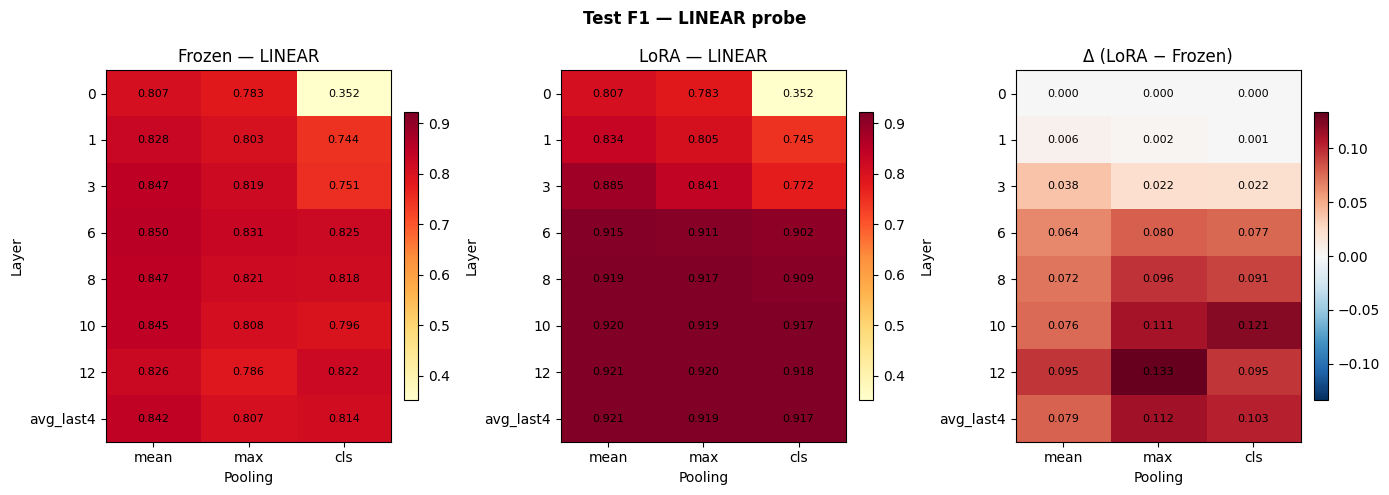

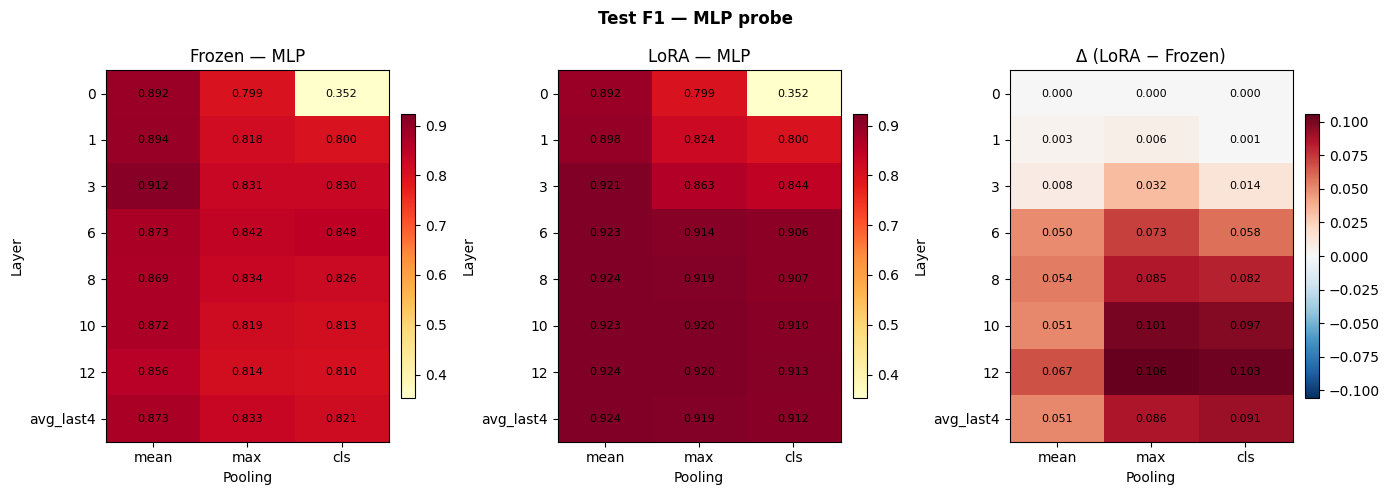

In [15]:
# ---- C. paired heatmaps ----
layer_order = ['0', '1', '3', '6', '8', '10', '12', 'avg_last4']
pool_order  = ['mean', 'max', 'cls']

def pivot(df_, probe_type, value_col):
    sub = df_[df_['probe'] == probe_type]
    pt  = sub.pivot(index='layer', columns='pooling', values=value_col)
    return pt.reindex(index=layer_order, columns=pool_order)

for probe_type in PROBE_TYPES:
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))

    fz = pivot(frozen_agg, probe_type, 'test_f1_mean')
    lo = pivot(lora_agg,   probe_type, 'test_f1_mean')
    dl = lo - fz

    # Shared scale for frozen / lora panels so the reader can compare colors directly
    vmin = float(min(fz.min().min(), lo.min().min()))
    vmax = float(max(fz.max().max(), lo.max().max()))

    for ax, data, title, cmap, kwargs in [
        (axes[0], fz, f'Frozen — {probe_type.upper()}', 'YlOrRd', dict(vmin=vmin, vmax=vmax)),
        (axes[1], lo, f'LoRA — {probe_type.upper()}',   'YlOrRd', dict(vmin=vmin, vmax=vmax)),
        (axes[2], dl, f'Δ (LoRA − Frozen)',             'RdBu_r', dict(vmin=-abs(dl.abs().max().max()),
                                                                       vmax= abs(dl.abs().max().max()))),
    ]:
        im = ax.imshow(data.values, cmap=cmap, aspect='auto', **kwargs)
        ax.set_xticks(range(len(pool_order)));  ax.set_xticklabels(pool_order)
        ax.set_yticks(range(len(layer_order))); ax.set_yticklabels(layer_order)
        ax.set_xlabel('Pooling'); ax.set_ylabel('Layer')
        ax.set_title(title)
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                v = data.iloc[i, j]
                if pd.isna(v):
                    continue
                ax.text(j, i, f'{v:.3f}', ha='center', va='center',
                        fontsize=8, color='black')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.suptitle(f'Test F1 — {probe_type.upper()} probe', fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'heatmap_frozen_vs_lora_{probe_type}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [16]:
# ---- D. best-layer migration ----
print('=' * 78)
print('Best-layer analysis (val-selected, per probe)')
print('=' * 78)

for pt in PROBE_TYPES:
    fz = frozen_agg[frozen_agg['probe'] == pt]
    lo = lora_agg  [lora_agg  ['probe'] == pt]
    fz_best = fz.loc[fz['val_f1_mean'].idxmax()]
    lo_best = lo.loc[lo['val_f1_mean'].idxmax()]

    print(f'\n{pt.upper()} probe')
    print(f'  Frozen best: layer={fz_best["layer"]:>9s}  pool={fz_best["pooling"]}  '
          f'test_F1={fz_best["test_f1_mean"]:.4f}')
    print(f'  LoRA   best: layer={lo_best["layer"]:>9s}  pool={lo_best["pooling"]}  '
          f'test_F1={lo_best["test_f1_mean"]:.4f}')
    moved = (fz_best['layer'] != lo_best['layer']) or (fz_best['pooling'] != lo_best['pooling'])
    tag   = 'MIGRATED' if moved else 'unchanged'
    gain  = lo_best['test_f1_mean'] - fz_best['test_f1_mean']
    print(f'  Best-config change: {tag}    Δ test_F1 = {gain:+.4f}')

Best-layer analysis (val-selected, per probe)

LINEAR probe
  Frozen best: layer=        3  pool=mean  test_F1=0.8473
  LoRA   best: layer=       12  pool=mean  test_F1=0.9212
  Best-config change: MIGRATED    Δ test_F1 = +0.0739

MLP probe
  Frozen best: layer=        3  pool=mean  test_F1=0.9121
  LoRA   best: layer=       12  pool=max  test_F1=0.9201
  Best-config change: MIGRATED    Δ test_F1 = +0.0079


## 7. Final Combined Table (for report)

Includes three classes of results:

1. **Frozen probing** (Notebook 02 v2) — upper bound of pretrained representations
2. **LoRA probing** (this notebook) — representation quality after adaptation
3. **End-to-end LoRA** (deployment baseline) — numbers carried forward from earlier runs

Rows 1 and 2 form the *controlled comparison* (same probe, same split, different backbone).
Row 3 is a *deployment viewpoint*: what a practitioner would get by just training LoRA with a
linear head on top of L12 — not directly comparable to the probing rows, but informative.

In [17]:
def fmt(mu, sd):
    return f'{mu:.4f} ± {sd:.4f}'

def pick_best(agg_df, probe_type):
    sub  = agg_df[agg_df['probe'] == probe_type]
    return sub.loc[sub['val_f1_mean'].idxmax()]

rows = []

# -- Frozen probe rows --
for pt in PROBE_TYPES:
    b = pick_best(frozen_agg, pt)
    rows.append({
        'Setting': f'Frozen + {pt.upper()} probe (L{b["layer"]}, {b["pooling"]})',
        'Category': 'Controlled probing — frozen backbone',
        'Test F1':  fmt(b['test_f1_mean'],  b['test_f1_std']),
        'Test Acc': fmt(b['test_acc_mean'], b['test_acc_std']),
        'Test MCC': fmt(b['test_mcc_mean'], b['test_mcc_std']),
    })

# -- LoRA probe rows --
for pt in PROBE_TYPES:
    b = pick_best(lora_agg, pt)
    rows.append({
        'Setting': f'LoRA + {pt.upper()} probe (L{b["layer"]}, {b["pooling"]})',
        'Category': 'Controlled probing — LoRA-tuned backbone',
        'Test F1':  fmt(b['test_f1_mean'],  b['test_f1_std']),
        'Test Acc': fmt(b['test_acc_mean'], b['test_acc_std']),
        'Test MCC': fmt(b['test_mcc_mean'], b['test_mcc_std']),
    })

# -- End-to-end LoRA baselines (carried forward — no re-run) --
rows.append({
    'Setting': 'LoRA FT (Q+V only, r=8) + Linear head (L12, mean)',
    'Category': 'End-to-end LoRA (deployment baseline)',
    'Test F1':  '0.8716 ± 0.0041',
    'Test Acc': '0.8717 ± 0.0041',
    'Test MCC': '0.7512 ± 0.0085',
})
rows.append({
    'Setting': 'LoRA FT (Wqkv + FFN, r=8) + Linear head (L12, mean)',
    'Category': 'End-to-end LoRA (deployment baseline)',
    'Test F1':  '0.9200 ± 0.0043',
    'Test Acc': '0.9202 ± 0.0044',
    'Test MCC': '0.8449 ± 0.0066',
})

final_df = pd.DataFrame(rows)
print(final_df.to_string(index=False))
final_df.to_csv('final_report_table.csv', index=False)
print('\nFinal table saved to final_report_table.csv')

                                            Setting                                 Category         Test F1        Test Acc        Test MCC
                   Frozen + LINEAR probe (L3, mean)     Controlled probing — frozen backbone 0.8473 ± 0.0006 0.8474 ± 0.0006 0.7019 ± 0.0010
                      Frozen + MLP probe (L3, mean)     Controlled probing — frozen backbone 0.9121 ± 0.0031 0.9125 ± 0.0030 0.8257 ± 0.0067
                    LoRA + LINEAR probe (L12, mean) Controlled probing — LoRA-tuned backbone 0.9212 ± 0.0001 0.9214 ± 0.0001 0.8442 ± 0.0003
                        LoRA + MLP probe (L12, max) Controlled probing — LoRA-tuned backbone 0.9201 ± 0.0012 0.9204 ± 0.0012 0.8412 ± 0.0031
  LoRA FT (Q+V only, r=8) + Linear head (L12, mean)    End-to-end LoRA (deployment baseline) 0.8716 ± 0.0041 0.8717 ± 0.0041 0.7512 ± 0.0085
LoRA FT (Wqkv + FFN, r=8) + Linear head (L12, mean)    End-to-end LoRA (deployment baseline) 0.9200 ± 0.0043 0.9202 ± 0.0044 0.8449 ± 0.0066

Final table 

## Discussion anchors for the report

Things to address in Section 4.3 of the report once the numbers are in:

1. **Does LoRA improve representations at all?** Compare `LoRA + MLP (best)` vs `Frozen + MLP (best)` in the table above. If the LoRA row is higher, fine-tuning genuinely adds information — not just re-routes existing features.
2. **Where does the improvement come from?** The Δ heatmap (§6 C) shows per-cell gains. If gains concentrate in deeper layers (L10–L12), LoRA is specializing the tail for the task; if gains are spread across layers, it's enhancing representations globally.
3. **Does the best layer migrate?** If the frozen best was L3 and the LoRA best moved to L10+, it suggests LoRA undoes the "last-layer specialization" penalty (Li et al. NeurIPS-W 2022). If the best stayed at L3, the hierarchy of useful features is a property of the architecture, not of training status.
4. **End-to-end vs two-stage.** Compare `LoRA + MLP probe` with `LoRA + Linear head` (0.9200). If the two-stage number is higher, the bottleneck in the deployment baseline was head capacity, not LoRA. If comparable, the classifier complexity doesn't matter much once the backbone is adapted.
5. **Connection to midterm finding.** Our midterm observed that on the frozen backbone, MLP best = L3 (F1 = 0.9277) — far from the final layer. Replacing the frozen backbone with a LoRA-tuned one is a direct test of whether this "intermediate-layer preference" is a representational property or a training-regime artifact.